# Этап 5. Метрики и валидация: MAE/RMSE/WAPE/MAPE/MASE, time-based split, backtesting

Holdout — одна точка оценки. Backtesting скользящим окном — 5 фолдов по 28 дней:
среднее и разброс WAPE вместо одного числа.

In [2]:
import sys
import time
import warnings
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.holtwinters import ExponentialSmoothing

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.helpers import save_fig, save_table

warnings.simplefilter("ignore")
plt.rcParams["figure.figsize"] = (10, 4)

In [3]:
# данные + ряд CA_3
DATA = ROOT / "data" / "raw"
sales = pd.read_csv(DATA / "sales_train_validation.csv")
calendar = pd.read_csv(DATA / "calendar.csv")
day_cols = [c for c in sales.columns if c.startswith("d_")]

ca_3 = sales.loc[sales["store_id"] == "CA_3", day_cols].sum()
s = pd.Series(ca_3.values,
             index=pd.to_datetime(calendar["date"].iloc[:len(day_cols)]),
             name="sales").astype("float64")
print(f"{s.index.min().date()} -> {s.index.max().date()} | дней: {len(s)}")

2011-01-29 -> 2016-04-24 | дней: 1913


## 1. Метрики: формулы и подводные камни

- **MAE** — средний |ошибка|, штуки.
- **RMSE** — sqrt среднего квадрата: больнее за большие промахи.
- **WAPE** = MAE / сумма факта, % — главная метрика проекта.
- **MAPE** — средний |ошибка / факт|: делит на факт дня, обманывает на малых объёмах.
- **MASE** = MAE / средний |сезонный шаг| train (m=7); MASE < 1 — лучше наивного.

In [4]:
# реализации метрик
def mae(y_fact, y_pred):
    return float(np.mean(np.abs(y_fact - y_pred)))

def rmse(y_fact, y_pred):
    return float(np.sqrt(np.mean((y_fact - y_pred)**2)))

def wape(y_fact, y_pred):
    return float(100 * np.abs(y_fact - y_pred).sum() / np.abs(y_fact).sum())

def mape(y_fact, y_pred):
    yf, yp = np.asarray(y_fact, dtype=float), np.asarray(y_pred, dtype=float)
    mask = yf != 0
    return float(100 * np.mean(np.abs(yf[mask] - yp[mask]) / yf[mask]))

def mase(y_fact, y_pred, train, m=7):
    t = np.asarray(train, dtype=float)
    scale = np.abs(t[m:] - t[:-m]).mean()
    return float(mae(y_fact, y_pred) / scale)

def metrics_row(y_fact, y_pred, name, train=None):
    row = {
        "модель": name,
        "MAE": round(mae(y_fact, y_pred), 1),
        "RMSE": round(rmse(y_fact, y_pred), 1),
        "WAPE, %": round(wape(y_fact, y_pred), 1),
    }
    if train is not None:
        row["MASE"] = round(mase(y_fact, y_pred, train), 2)
    return row

In [5]:
# демонстрация: две модели на 5 днях — какая лучше?
demo = pd.DataFrame({
    "y_fact": [100.0, 200.0, 300.0, 400.0, 5000.0],
    "прогноз А - мелкие промахи": [100.0, 190.0, 310.0, 390.0, 5000.0],
    "прогноз В - один большой промах": [100.0, 200.0, 300.0, 400.0, 4600.0],
})

rows = []
for col in demo.columns[1:]:
    rows.append({
        "прогноз": col,
        "MAE": mae(demo["y_fact"], demo[col]),
        "RMSE": rmse(demo["y_fact"], demo[col]),
        "WAPE, %": wape(demo["y_fact"], demo[col]),
        "MAPE, %": mape(demo["y_fact"], demo[col])
    })
demo_table = pd.DataFrame(rows).round(2)
save_table(demo_table, "05_val_metric_examples")
demo_table

,прогноз,MAE,RMSE,"WAPE, %","MAPE, %"
0,прогноз А - мелкие промахи,6.0,7.75,0.50,2.17
1,прогноз В - один большой промах,80.0,178.89,6.67,1.60


**Вывод:** по MAPE лучше прогноз B (1.6% против 4.2%) — а на деле B промахнулся
на 400 штук в самый большой день. MAPE «не видит» промахов на больших объёмах,
WAPE и RMSE честно наказывают B в 10–20 раз сильнее. Поэтому главная — WAPE.

## 2. Time-based split

Train — всё до отсечки, test — последние 28 дней. Перемешивание и k-fold
на рядах запрещены: модель увидит будущее. Фолд 5 в backtesting ниже —
это ровно этот holdout.

In [6]:
# holdout как в этапе 4
H = 28
train_ho, test_ho = s.iloc[:-H], s.iloc[-H:]
print(f"train: {train_ho.index.min().date()} .. {train_ho.index.max().date()} ({len(train_ho)} дн)")
print(f"test: {test_ho.index.min().date()} .. {test_ho.index.max().date()} ({len(test_ho)} дн)")

train: 2011-01-29 .. 2016-03-27 (1885 дн)
test: 2016-03-28 .. 2016-04-24 (28 дн)


In [7]:
# модели как функции: train -> прогноз длиной H
# порядок SARIMA — из этапов 3–4; если в 04_baselines у тебя финальный порядок другой, подставь свой
def m_naive_1(train):
    return np.full(H, train.iloc[-1])

def m_naive_28(train):
    return train.iloc[-28:].values.astype(float)

def m_ma_28(train):
    return np.full(H, train.iloc[-28:].mean())

def m_hw(train):
    fit = ExponentialSmoothing(train, trend="add", seasonal="add",
                              seasonal_periods=7,
                              initialization_method="estimated").fit()
    return fit.forecast(H).values

def m_sarima(train):
    fit = sm.tsa.SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 7),
                        enforce_stationarity=False,
                        enforce_invertibility=False).fit(disp=False)
    return fit.forecast(H).values

models = {
    "Наивный (последний день)": m_naive_1,
    "Наивный (значение 28 дней назад)": m_naive_28,
    "Скользящее среднее (28 дней)": m_ma_28,
    "Holt-Winters": m_hw,
    "SARIMA (1,1,1)x(1,1,1,7)": m_sarima,
}

In [8]:
# метрики на holdout (та же таблица, что в этапе 4 — для сравнения с backtest)
ho = pd.DataFrame([metrics_row(test_ho.values, np.asarray(fn(train_ho)), name)
                  for name, fn in models.items()])
ho

,модель,MAE,RMSE,"WAPE, %"
0,Наивный (последний день),1509.9,1696.6,23.9
1,Наивный (значение 28 дней назад),379.0,471.0,6.0
2,Скользящее среднее (28 дней),929.6,1063.6,14.7
3,Holt-Winters,407.4,472.1,6.4
4,"SARIMA (1,1,1)x(1,1,1,7)",366.7,429.9,5.8


## 3. Backtesting скользящим окном

5 фолдов по 28 дней: train расширяется, test сдвигается вперёд.
Фолд 5 — тот же отрезок, что holdout в этапе 4.

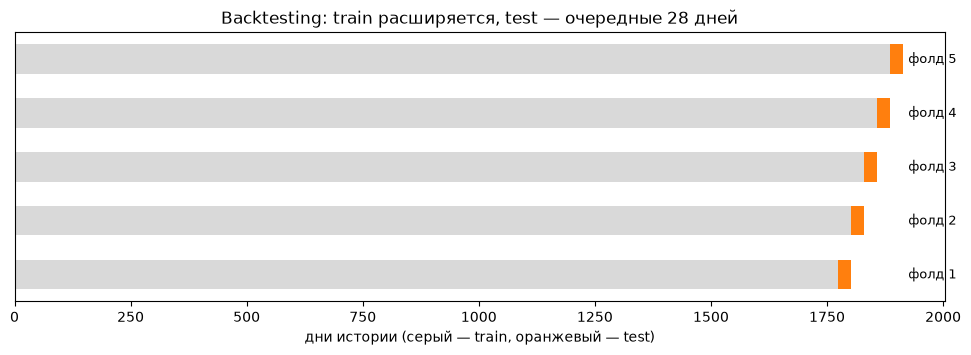

In [11]:
# схема фолдов
N_FOLDS = 5

fig, ax = plt.subplots(figsize=(12, 3.5))
n = len(s)
for k in range(N_FOLDS):
    t_0 = n - H * (N_FOLDS - k)
    ax.barh(k, t_0, color="0.85", height=0.55)
    ax.barh(k, H, left=t_0, color="#ff7f0e", height=0.55)
    ax.text(n + 12, k, f"фолд {k + 1}", va="center", fontsize=9)
ax.set_xlim(0, n + 90)
ax.set_yticks([])
ax.set_xlabel("дни истории (серый — train, оранжевый — test)")
ax.set_title("Backtesting: train расширяется, test — очередные 28 дней")
save_fig(ax, "05_val_backtest_scheme")

In [12]:
# backtest: expanding train, test = очередные 28 дней
def backtest(series, model_fn, n_folds=N_FOLDS, horizon=H):
    rows, preds = [], {}
    for k in range(n_folds):
        t_0 = len(series) - horizon * (n_folds - k)
        train = series.iloc[:t_0]
        test = series.iloc[t_0:t_0 + horizon]
        pred = np.asarray(model_fn(train), dtype=float)
        preds[k + 1] = pred
        row = metrics_row(test.values, pred, "")
        row.pop("модель")
        rows.append({
            "фолд": k + 1,
            "train_end": train.index.max().date(),
            "test": f"{test.index.min().date()} .. {test.index.max().date()}",
            **row
        })
    return pd.DataFrame(rows), preds

In [13]:
# прогон всех моделей по всем фолдам
bt, preds = {}, {}
for name, fn in models.items():
    t = time.time()
    bt[name], preds[name] = backtest(s, fn)
    print(f"{name}: {time.time() - t:.1f} ")

folds_table = pd.concat([df.assign(модель=name) for name, df in bt.items()])
save_table(folds_table, "05_val_backtest_folds")
folds_table

Наивный (последний день): 0.0 
Наивный (значение 28 дней назад): 0.0 
Скользящее среднее (28 дней): 0.0 
Holt-Winters: 1.7 
SARIMA (1,1,1)x(1,1,1,7): 21.4 


,фолд,train_end,test,MAE,RMSE,"WAPE, %",модель
0,1,2015-12-06,2015-12-07 .. 2016-01-03,1993.6,2336.4,37.3,Наивный (последний день)
1,2,2016-01-03,2016-01-04 .. 2016-01-31,1213.9,1303.0,19.9,Наивный (последний день)
2,3,2016-01-31,2016-02-01 .. 2016-02-28,1682.2,1868.3,26.2,Наивный (последний день)
3,4,2016-02-28,2016-02-29 .. 2016-03-27,1489.6,1708.0,23.0,Наивный (последний день)
4,5,2016-03-27,2016-03-28 .. 2016-04-24,1509.9,1696.6,23.9,Наивный (последний день)
0,1,2015-12-06,2015-12-07 .. 2016-01-03,513.7,888.6,9.6,Наивный (значение 28 дней назад)
1,2,2016-01-03,2016-01-04 .. 2016-01-31,897.4,1355.8,14.7,Наивный (значение 28 дней назад)
2,3,2016-01-31,2016-02-01 .. 2016-02-28,555.4,716.5,8.7,Наивный (значение 28 дней назад)
3,4,2016-02-28,2016-02-29 .. 2016-03-27,416.2,593.3,6.4,Наивный (значение 28 дней назад)
4,5,2016-03-27,2016-03-28 .. 2016-04-24,379.0,471.0,6.0,Наивный (значение 28 дней назад)


In [15]:
# сводка: среднее и разброс по фолдам
summary = folds_table.groupby("модель").agg(
    фолдов=("WAPE, %", "count"),
    MAE_mean=("MAE", "mean"),
    MAE_std=("MAE", "std"),
    WAPE_mean=("WAPE, %", "mean"),
    WAPE_std=("WAPE, %", "std"),
).round({
    "MAE_mean": 1,
    "MAE_std": 1,
    "WAPE_mean": 1,
    "WAPE_std": 1
})
save_table(summary.reset_index(), "05_val_backtest_summary")
summary

,фолдов,MAE_mean,MAE_std,WAPE_mean,WAPE_std
модель,,,,,
Holt-Winters,5,456.0,185.3,7.6,3.6
"SARIMA (1,1,1)x(1,1,1,7)",5,495.8,217.8,8.2,3.8
Наивный (значение 28 дней назад),5,552.3,205.6,9.1,3.5
Наивный (последний день),5,1577.8,286.6,26.1,6.7
Скользящее среднее (28 дней),5,804.0,128.9,13.1,2.0


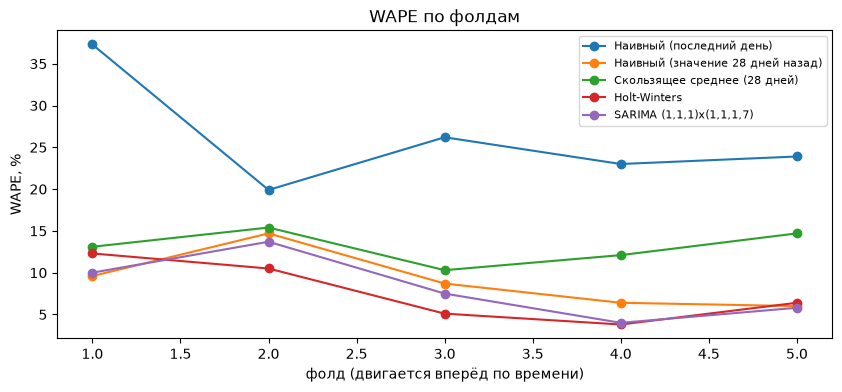

In [16]:
# WAPE по фолдам: кто стабилен, кому повезло с одним отрезком
fig, ax = plt.subplots()
for name, df in bt.items():
    ax.plot(df["фолд"], df["WAPE, %"], marker="o", label=name)
ax.set_xlabel("фолд (двигается вперёд по времени)")
ax.set_ylabel("WAPE, %")
ax.set_title("WAPE по фолдам")
ax.legend(fontsize=8)
save_fig(ax, "05_val_backtest_wape_by_fold")

In [17]:
# holdout (одно окно) против backtest (среднее по 5 фолдам)
cmp = ho.merge(summary[["WAPE_mean", "WAPE_std"]], left_on="модель", right_index=True)
cmp = cmp.rename(columns={
    "WAPE, %": "WAPE holdout, %",
    "WAPE_mean": "WAPE backtest, среднее",
    "WAPE_std": "WAPE backtest, std"
})
save_table(cmp, "05_val_holdout_vs_backtest")
cmp

,модель,MAE,RMSE,"WAPE holdout, %","WAPE backtest, среднее","WAPE backtest, std"
0,Наивный (последний день),1509.9,1696.6,23.9,26.1,6.7
1,Наивный (значение 28 дней назад),379.0,471.0,6.0,9.1,3.5
2,Скользящее среднее (28 дней),929.6,1063.6,14.7,13.1,2.0
3,Holt-Winters,407.4,472.1,6.4,7.6,3.6
4,"SARIMA (1,1,1)x(1,1,1,7)",366.7,429.9,5.8,8.2,3.8


**Вывод:** устойчивая модель — низкое среднее И малый std. Модель с хорошим
holdout, но плохим средним по фолдам — просто повезло с отрезком.

## 4. Профиль ошибки по горизонту

WAPE отдельно для каждого дня h=1..28, усреднённый по фолдам:
как быстро деградирует прогноз с дальностью. Сравни, у кого профиль
самый плоский, а у кого самый крутой.

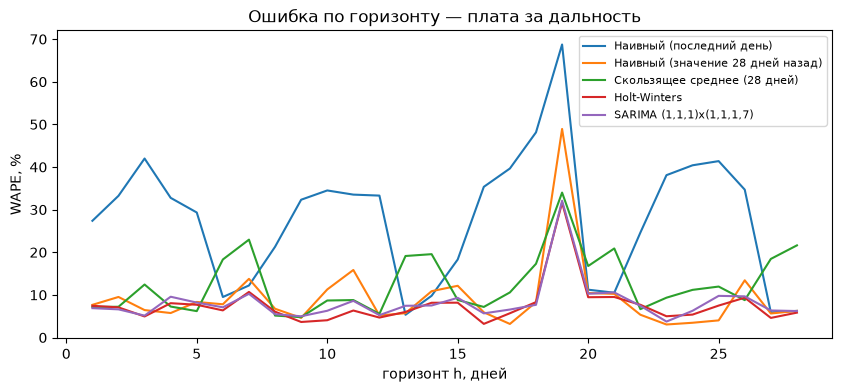

In [19]:
# WAPE по дням горизонта: суммы |ошибки| и факта по всем фолдам
profs = {}
for name, p in preds.items():
    abs_err = np.zeros(H)
    fact = np.zeros(H)
    for k in range(N_FOLDS):
        t_0 = len(s) - H * (N_FOLDS - k)
        test = s.iloc[t_0:t_0 + H].values
        abs_err += np.abs(test - preds[name][k + 1])
        fact += test
    profs[name] = 100 * abs_err / fact

fig, ax = plt.subplots()
for name, prof in profs.items():
    ax.plot(range(1, H + 1), prof, label=name)
ax.set_xlabel("горизонт h, дней")
ax.set_ylabel("WAPE, %")
ax.set_title("Ошибка по горизонту — плата за дальность")
ax.legend(fontsize=8)
save_fig(ax, "05_val_wape_by_horizon")

## Упражнение: backtest для TX_3

In [21]:
# упражнение: ряд TX_3 + backtest
tx_3 = sales.loc[sales["store_id"] == "TX_3", day_cols].sum()
s_tx = pd.Series(tx_3.values, index=s.index, name="sales_tx3").astype("float64")

models_tx = {
    "Наивный (последний день)": m_naive_1,
    "Наивный (значение 28 дней назад)": m_naive_28,
    "Скользящее среднее (28 дней)": m_ma_28,
    "Holt-Winters": m_hw,
}

bt_tx, preds_tx = {}, {}
for name, fn in models_tx.items():
    bt_tx[name], preds_tx[name] = backtest(s_tx, fn)

tx_table = pd.concat([df.assign(модель=name) for name, df in bt_tx.items()])
save_table(tx_table, "05_ex_tx3_backtest_folds")
tx_table

,фолд,train_end,test,MAE,RMSE,"WAPE, %",модель
0,1,2015-12-06,2015-12-07 .. 2016-01-03,790.0,1071.7,23.7,Наивный (последний день)
1,2,2016-01-03,2016-01-04 .. 2016-01-31,468.6,540.9,12.9,Наивный (последний день)
2,3,2016-01-31,2016-02-01 .. 2016-02-28,726.2,856.7,18.5,Наивный (последний день)
3,4,2016-02-28,2016-02-29 .. 2016-03-27,597.6,701.4,15.5,Наивный (последний день)
4,5,2016-03-27,2016-03-28 .. 2016-04-24,423.9,508.6,11.2,Наивный (последний день)
0,1,2015-12-06,2015-12-07 .. 2016-01-03,426.6,648.3,12.8,Наивный (значение 28 дней назад)
1,2,2016-01-03,2016-01-04 .. 2016-01-31,555.5,875.8,15.3,Наивный (значение 28 дней назад)
2,3,2016-01-31,2016-02-01 .. 2016-02-28,404.5,514.4,10.3,Наивный (значение 28 дней назад)
3,4,2016-02-28,2016-02-29 .. 2016-03-27,426.2,499.5,11.0,Наивный (значение 28 дней назад)
4,5,2016-03-27,2016-03-28 .. 2016-04-24,315.0,413.2,8.3,Наивный (значение 28 дней назад)


In [22]:
# ответ b: те же модели на одноразовом holdout TX_3
ho_tx = pd.DataFrame([metrics_row(s_tx.iloc[-H:].values,
                                  np.asarray(fn(s_tx.iloc[:-H])), name)
                      for name, fn in models_tx.items()])
ho_tx

,модель,MAE,RMSE,"WAPE, %"
0,Наивный (последний день),423.9,508.6,11.2
1,Наивный (значение 28 дней назад),315.0,413.2,8.3
2,Скользящее среднее (28 дней),392.6,476.3,10.3
3,Holt-Winters,241.8,315.9,6.4


In [23]:
# ответы a и c: среднее и разброс по фолдам
tx_summary = tx_table.groupby("модель").agg(
    фолдов=("WAPE, %", "count"),
    WAPE_mean=("WAPE, %", "mean"),
    WAPE_std=("WAPE, %", "std"),
).round({"WAPE_mean": 1, "WAPE_std": 1})
save_table(tx_summary.reset_index(), "05_ex_tx3_backtest_summary")
tx_summary

,фолдов,WAPE_mean,WAPE_std
модель,,,
Holt-Winters,5,9.7,2.9
Наивный (значение 28 дней назад),5,11.5,2.6
Наивный (последний день),5,16.4,4.9
Скользящее среднее (28 дней),5,11.4,1.9


SARIMA не включаем — считалась бы в 5 раз дольше, на вывод не влияет.
Ответь на вопросы:

a) какая модель лучшая по среднему WAPE в backtest?
    
    Ответ: самая модель лучшая по среднему WAPE в backtest является - Holt-Winters (9.7); 

b) совпадает ли она с победителем на одноразовом holdout (последние 28 дней)?
    
    Ответ: не совпадает. На одноразовом holdout (последние 28 дней) резульат лучше (6.4);

c) у какой модели наибольший std WAPE между фолдами и что это значит?
    
    Ответ: у модели «Наивный (последний день)» наибольший std WAPE (4.9), что почти вдвое превышает разброс у Holt-Winters (2.9) и втрое — у скользящего среднего (1.9). Это значит, что модель крайне нестабильна: её качество сильно зависит от конкретного фолда (среза данных). На одних неделях она может давать приемлемый прогноз, а на других — резко проваливаться. Причина проста: она копирует одно единственное значение, поэтому любой выброс или нестандартное событие в последний день обучения (праздник, акция, сбой) мгновенно переносится на весь горизонт прогноза, не имея механизма усреднения.